# YOLOv8-Small: Bottle on Shelves Detection

Train a YOLOv8s detector on 3 classes (coca, fanta, sprite) for shelf inventory analytics.

**Before running:** upload `dataset.zip` to this notebook's working directory (left panel → Files → upload).

## 1. GPU Check

In [2]:
import torch
assert torch.cuda.is_available(), "No GPU! Runtime → Change runtime type → GPU"
print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

GPU: Tesla T4
VRAM: 15.6 GB


## 2. Install ultralytics

In [3]:
!pip install -q ultralytics>=8.0.0
import ultralytics
ultralytics.checks()

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 42.5/112.6 GB disk)


## 3. Unzip dataset & fix data.yaml paths

The Roboflow export uses relative paths (`../train/images`) that break in Colab.
We rewrite them to absolute paths so YOLO finds the splits.

In [4]:
import yaml, os
from pathlib import Path

# Unzip
!unzip -q dataset.zip -d dataset

# Fix data.yaml paths to absolute
yaml_path = Path('dataset/data.yaml')
data = yaml.safe_load(yaml_path.read_text())
root = yaml_path.parent.resolve()

for split in ['train', 'val', 'test']:
    key = split if split != 'val' else 'val'
    rel = data.get(key, '')
    # '../train/images' → 'dataset/train/images'
    folder = rel.replace('../', '')
    data[key] = str(root / folder)

yaml_path.write_text(yaml.dump(data, default_flow_style=False))
print('Fixed data.yaml:')
print(yaml_path.read_text())

# Sanity check
for split in ['train', 'val', 'test']:
    p = Path(data[split])
    n = len(list(p.glob('*.jpg'))) + len(list(p.glob('*.png')))
    print(f'{split}: {n} images at {p}')

Fixed data.yaml:
names:
- coca
- fanta
- sprite
nc: 3
roboflow:
  license: CC BY 4.0
  project: bottle-on-shelves
  url: https://universe.roboflow.com/object-usecase/bottle-on-shelves/dataset/4
  version: 4
  workspace: object-usecase
test: /content/dataset/test/images
train: /content/dataset/train/images
val: /content/dataset/valid/images

train: 99 images at /content/dataset/train/images
val: 36 images at /content/dataset/valid/images
test: 15 images at /content/dataset/test/images


## 4. Train YOLOv8s

In [5]:
from ultralytics import YOLO

model = YOLO('yolov8s.pt')
results = model.train(
    data='dataset/data.yaml',
    epochs=50,
    batch=16,
    imgsz=640,
    name='bottle_yolov8s',
    patience=10,
    save=True,
    device=0,
)
print(f'Best mAP50: {results.results_dict.get("metrics/mAP50(B)", "N/A"):.4f}')

Ultralytics 8.4.190 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=bottle_yolov8s, nbs=64, nms=None, opset=None, optimize=False, optimizer

## 5. Training curves

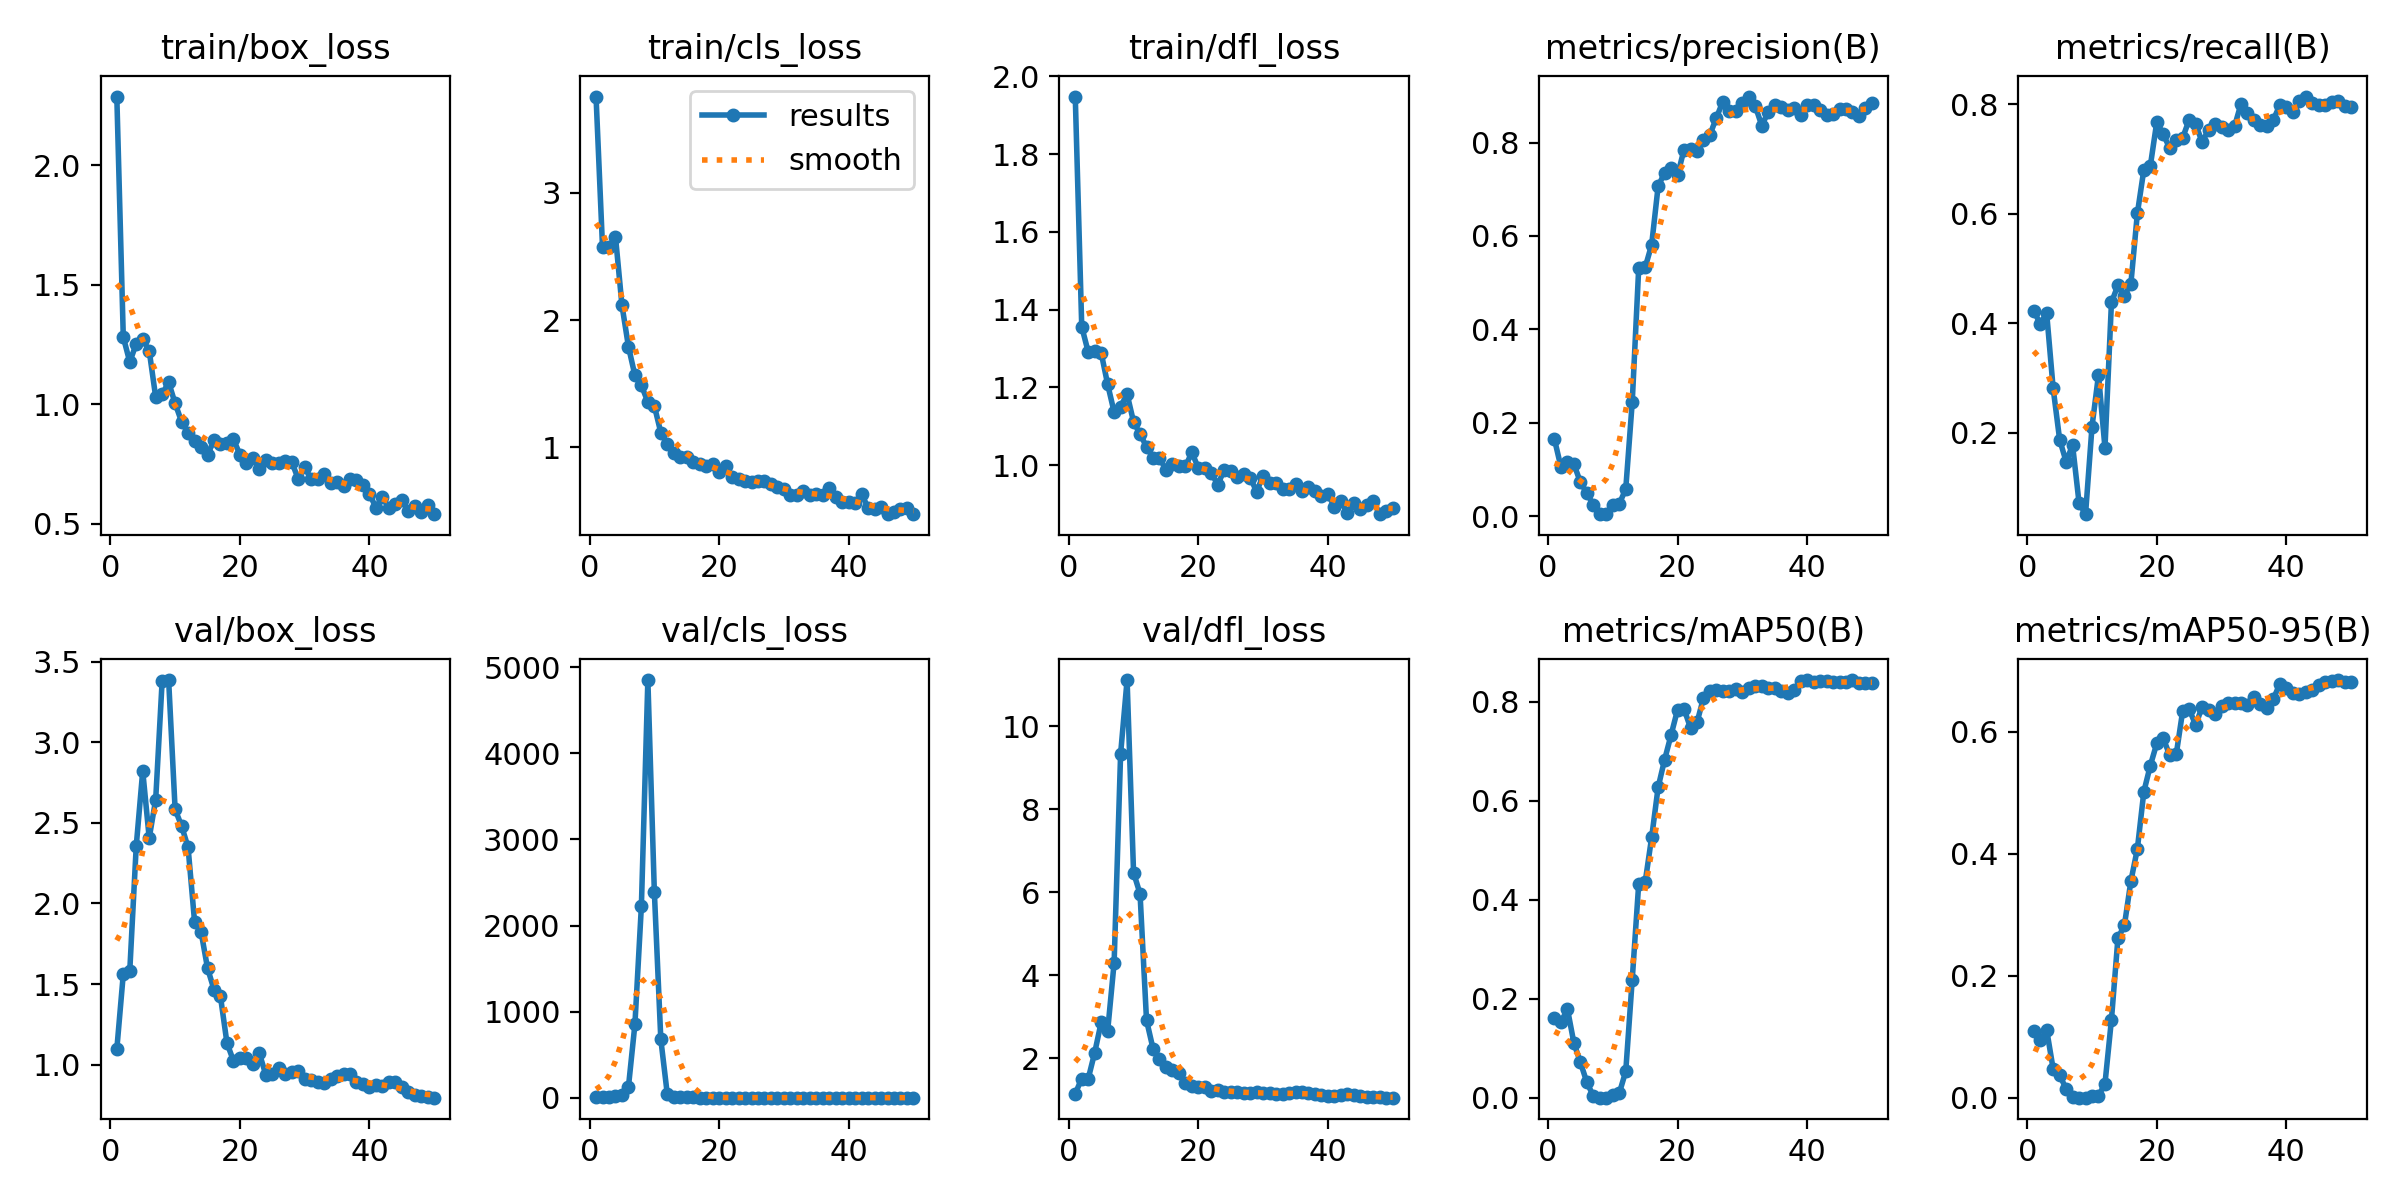

In [6]:
from IPython.display import Image
import glob

runs = sorted(glob.glob('runs/detect/bottle_yolov8s*/results.png'))
assert runs, 'No results.png found — training may have failed.'
Image(filename=runs[-1], width=900)

## 6. Inference on test set & download best.pt

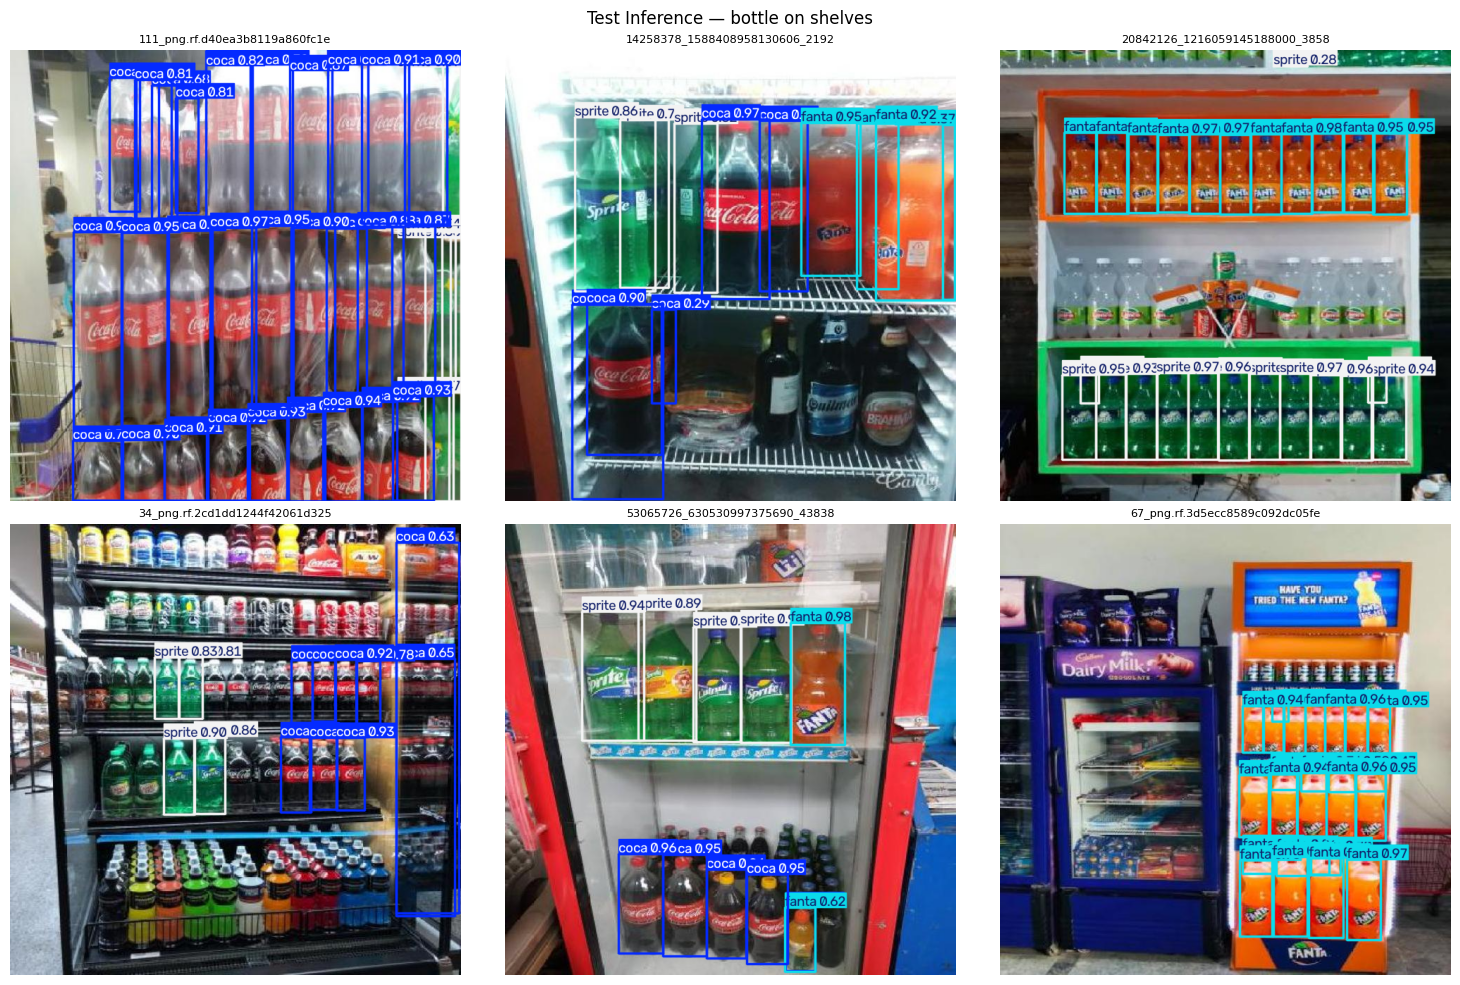

In [7]:
import matplotlib.pyplot as plt
from pathlib import Path

best = YOLO(runs[-1].replace('results.png', 'weights/best.pt'))
test_imgs = sorted(glob.glob('dataset/test/images/*'))[:6]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, img_path in zip(axes.flat, test_imgs):
    res = best(img_path, verbose=False)[0]
    ax.imshow(res.plot()[:, :, ::-1])  # BGR→RGB
    ax.set_title(Path(img_path).stem[:30], fontsize=8)
    ax.axis('off')
plt.suptitle('Test Inference — bottle on shelves', fontsize=12)
plt.tight_layout()
plt.show()

In [8]:
from google.colab import files

best_path = runs[-1].replace('results.png', 'weights/best.pt')
files.download(best_path)
print(f'Downloaded: {best_path}')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded: runs/detect/bottle_yolov8s/weights/best.pt
